In [ ]:
print("Welcome to CyberShield AI!")
print("Intelligent Threat Intelligence and Phishing Risk Analyzer")
print("Project setup started successfully!")

Welcome to CyberShield AI!
Intelligent Threat Intelligence and Phishing Risk Analyzer
Project setup started successfully!


In [ ]:
import pandas as pd
import requests

print("Pandas version:", pd.__version__)
print("Requests library is ready!")
print("CyberShield AI libraries checked successfully!")

Pandas version: 2.2.3
Requests library is ready!
CyberShield AI libraries checked successfully!


In [ ]:

from urllib.parse import urlparse
import re
import ipaddress

def analyze_url(url):
    url = url.strip()

    if not url.startswith(("http://", "https://")):
        url = "https://" + url

    parsed = urlparse(url)
    hostname = parsed.hostname

    if not hostname:
        return {"URL": url, "Result": "Invalid URL",
                "Indicators": ["Hostname missing"]}

    indicators = []

    # Check whether the connection uses HTTP
    if parsed.scheme == "http":
        indicators.append("Uses unencrypted HTTP")

    # Check whether the hostname is an IP address
    try:
        ipaddress.ip_address(hostname)
        indicators.append("Uses an IP address as hostname")
    except ValueError:
        pass

    # Check for a URL containing username/password
    if parsed.username or parsed.password:
        indicators.append("Contains user information in URL")

    # Check for potentially suspicious words
    words = ["login", "verify", "password",
             "account", "secure", "update"]

    text_to_check = (hostname + parsed.path).lower()
    found_words = [word for word in words if word in text_to_check]

    if found_words:
        indicators.append(
            "Sensitive words found: " + ", ".join(found_words)
        )

    if "xn--" in hostname.lower():
        indicators.append("Contains an internationalized hostname")

    if indicators:
        result = "Needs Further Review"
    else:
        result = "No Basic Warning Found"

    return {
        "URL": url,
        "Result": result,
        "Indicators": indicators
    }


# Test with a harmless example domain
test_url = "https://example.com"
report = analyze_url(test_url)

for key, value in report.items():
    print(f"{key}: {value}")


URL: https://example.com
Result: No Basic Warning Found
Indicators: []


In [ ]:
from getpass import getpass

VT_API_KEY = getpass("Enter your NEW VirusTotal API key: ")

print("API key received!")

Enter your NEW VirusTotal API key: ··········
API key received!


In [ ]:
import base64
import requests

def check_virustotal_url(url):
    # URL ni VirusTotal lookup format ki convert chestham
    url_id = base64.urlsafe_b64encode(
        url.encode()
    ).decode().strip("=")

    endpoint = f"https://www.virustotal.com/api/v3/urls/{url_id}"

    headers = {
        "x-apikey": VT_API_KEY
    }

    response = requests.get(
        endpoint,
        headers=headers,
        timeout=30
    )

    if response.status_code == 200:
        data = response.json()
        stats = data["data"]["attributes"].get(
            "last_analysis_stats", {}
        )

        print("URL:", url)
        print("Malicious detections:", stats.get("malicious", 0))
        print("Suspicious detections:", stats.get("suspicious", 0))
        print("Harmless detections:", stats.get("harmless", 0))
        print("Undetected:", stats.get("undetected", 0))

    elif response.status_code == 404:
        print("No existing VirusTotal report found for this URL.")

    elif response.status_code == 401:
        print("Authentication failed. Check your API key.")

    elif response.status_code == 429:
        print("API rate limit reached. Try again later.")

    else:
        print("Request failed:", response.status_code)
        print(response.text[:300])


check_virustotal_url("https://example.com")

URL: https://example.com
Malicious detections: 0
Suspicious detections: 0
Harmless detections: 62
Undetected: 31


In [ ]:

def cyber_shield_report(url):
    print("=" * 45)
    print("       CYBERSHIELD AI SECURITY REPORT")
    print("=" * 45)

    # Basic URL analysis
    basic = analyze_url(url)

    print("\n1. BASIC URL ANALYSIS")
    print("URL:", basic["URL"])
    print("Result:", basic["Result"])

    if basic["Indicators"]:
        for item in basic["Indicators"]:
            print("- ", item)
    else:
        print("No basic warning indicators found.")

    # VirusTotal report
    print("\n2. VIRUSTOTAL ANALYSIS")
    check_virustotal_url(basic["URL"])

    print("\nNote: Automated results are not a safety guarantee.")
    print("=" * 45)


cyber_shield_report("https://example.com")


       CYBERSHIELD AI SECURITY REPORT

1. BASIC URL ANALYSIS
URL: https://example.com
Result: No Basic Warning Found
No basic warning indicators found.

2. VIRUSTOTAL ANALYSIS
URL: https://example.com
Malicious detections: 0
Suspicious detections: 0
Harmless detections: 62
Undetected: 31

Note: Automated results are not a safety guarantee.


In [ ]:

url = input("Enter a URL to analyze: ")
cyber_shield_report(url)


Enter a URL to analyze: https://example.com
       CYBERSHIELD AI SECURITY REPORT

1. BASIC URL ANALYSIS
URL: https://example.com
Result: No Basic Warning Found
No basic warning indicators found.

2. VIRUSTOTAL ANALYSIS
URL: https://example.com
Malicious detections: 0
Suspicious detections: 0
Harmless detections: 62
Undetected: 31

Note: Automated results are not a safety guarantee.


In [ ]:

import ipywidgets as widgets
from IPython.display import display, clear_output

url_input = widgets.Text(
    value="https://example.com",
    placeholder="Enter a URL",
    description="URL:",
    layout=widgets.Layout(width="80%")
)

analyze_button = widgets.Button(
    description="Analyze URL",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def on_analyze_clicked(button):
    with output:
        clear_output()
        url = url_input.value.strip()

        if not url:
            print("Please enter a URL.")
            return

        try:
            cyber_shield_report(url)
        except Exception as error:
            print("Could not complete analysis:", error)

analyze_button.on_click(on_analyze_clicked)

display(
    widgets.HTML("<h2>🛡️ CyberShield AI</h2>")
)
display(url_input, analyze_button, output)


HTML(value='<h2>🛡️ CyberShield AI</h2>')

Text(value='https://example.com', description='URL:', layout=Layout(width='80%'), placeholder='Enter a URL')

Button(button_style='primary', description='Analyze URL', icon='search', style=ButtonStyle())

Output()

In [ ]:

def classify_risk(malicious, suspicious):
    if malicious >= 5:
        return "HIGH RISK"
    elif malicious > 0 or suspicious >= 3:
        return "MEDIUM RISK"
    elif suspicious > 0:
        return "LOW RISK - REVIEW"
    else:
        return "NO DETECTIONS REPORTED"


print(classify_risk(0, 0))
print(classify_risk(2, 0))
print(classify_risk(6, 0))


NO DETECTIONS REPORTED
MEDIUM RISK
HIGH RISK


In [ ]:

def cyber_shield_report_v2(url):
    print("=" * 45)
    print("       CYBERSHIELD AI SECURITY REPORT")
    print("=" * 45)

    basic = analyze_url(url)

    print("\n1. BASIC URL ANALYSIS")
    print("URL:", basic["URL"])
    print("Result:", basic["Result"])

    for indicator in basic["Indicators"]:
        print("-", indicator)

    print("\n2. VIRUSTOTAL ANALYSIS")

    stats = check_virustotal_url(basic["URL"])

    # check_virustotal_url currently prints results.
    # We will update it next to return statistics.
    print("\n3. RISK CLASSIFICATION")
    print("Risk classification integration is next.")

    print("\nNote: No automated result guarantees safety.")
    print("=" * 45)


In [ ]:

import base64
import ipaddress
import requests
import re
import pandas as pd
import ipywidgets as widgets

from urllib.parse import urlparse
from IPython.display import display, clear_output
from getpass import getpass

# ==========================================
# 1. API KEY
# ==========================================

VT_API_KEY = getpass("Enter your VirusTotal API key: ")

# ==========================================
# 2. BASIC URL ANALYSIS
# ==========================================

def analyze_url(url):
    url = url.strip()

    if not url:
        return {
            "URL": "",
            "Result": "Invalid URL",
            "Indicators": ["URL is empty"]
        }

    if not re.match(r"^https?://", url, re.I):
        url = "https://" + url

    parsed = urlparse(url)
    hostname = parsed.hostname

    if not hostname:
        return {
            "URL": url,
            "Result": "Invalid URL",
            "Indicators": ["Hostname missing"]
        }

    indicators = []

    if parsed.scheme.lower() == "http":
        indicators.append("Uses unencrypted HTTP")

    try:
        ipaddress.ip_address(hostname)
        indicators.append("Uses an IP address as hostname")
    except ValueError:
        pass

    if parsed.username or parsed.password:
        indicators.append("Contains user information in URL")

    words = [
        "login", "verify", "password",
        "account", "secure", "update"
    ]

    text_to_check = (hostname + parsed.path).lower()
    found_words = [word for word in words if word in text_to_check]

    if found_words:
        indicators.append(
            "Sensitive words found: " + ", ".join(found_words)
        )

    if "xn--" in hostname.lower():
        indicators.append("Contains an internationalized hostname")

    result = (
        "Needs Further Review"
        if indicators else "No Basic Warning Found"
    )

    return {
        "URL": url,
        "Result": result,
        "Indicators": indicators
    }

# ==========================================
# 3. VIRUSTOTAL LOOKUP
# ==========================================




# ==========================================
# 5. PROFESSIONAL SECURITY REPORT
# ==========================================

def cyber_shield_report(url):
    basic = analyze_url(url)

    print("=" * 55)
    print("       🛡️ CYBERSHIELD AI SECURITY REPORT")
    print("=" * 55)

    if basic["Result"] == "Invalid URL":
        print("Invalid URL. Please enter a valid URL.")
        return

    print("\n📌 URL DETAILS")
    print("-" * 55)

    report = {
        "URL": basic["URL"],
        "Basic Analysis": basic["Result"]
    }

    display(pd.DataFrame(
        report.items(),
        columns=["Check", "Result"]
    ))

    print("\n🔎 BASIC WARNING INDICATORS")

    if basic["Indicators"]:
        for indicator in basic["Indicators"]:
            print("⚠️", indicator)
    else:
        print("✅ No basic warning indicators found.")

    print("\n🌐 VIRUSTOTAL ANALYSIS")
    print("-" * 55)

    stats = check_virustotal_url(basic["URL"])

    if stats["status"] == "Report found":
        results = pd.DataFrame([
            ["Malicious", stats["malicious"]],
            ["Suspicious", stats["suspicious"]],
            ["Harmless", stats["harmless"]],
            ["Undetected", stats["undetected"]]
        ], columns=["Detection Type", "Count"])

        display(results)

        risk = classify_risk(
            stats["malicious"],
            stats["suspicious"]
        )

        print("\n🛡️ FINAL ASSESSMENT")
        print("VirusTotal Risk:", risk)

        if basic["Indicators"]:
            print("Basic Review: Warning indicators found")
        else:
            print("Basic Review: No basic warnings found")

    else:
        print("VirusTotal Status:", stats["status"])
        print("VirusTotal Risk: Not available")

        print("\n🛡️ FINAL ASSESSMENT")
        if basic["Indicators"]:
            print("Review recommended: Warning indicators found")
        else:
            print("No basic warnings found, but verification is incomplete")

    print("\n⚠️ Note: Automated results do not guarantee safety.")
    print("A missing report does not mean a URL is safe.")
    print("=" * 55)

# ==========================================
# 4. RISK CLASSIFICATION
# ==========================================

def classify_risk(malicious, suspicious):
    if malicious >= 5:
        return "HIGH RISK"
    elif malicious > 0 or suspicious >= 3:
        return "MEDIUM RISK"
    elif suspicious > 0:
        return "LOW RISK - REVIEW"
    else:
        return "NO DETECTIONS REPORTED"

# ==========================================
# 5. COMBINED SECURITY REPORT
# ==========================================

def cyber_shield_report(url):
    basic = analyze_url(url)

    print("=" * 48)
    print("       CYBERSHIELD AI SECURITY REPORT")
    print("=" * 48)

    print("\n1. BASIC URL ANALYSIS")
    print("URL:", basic["URL"])
    print("Result:", basic["Result"])

    if basic["Indicators"]:
        for item in basic["Indicators"]:
            print("-", item)
    else:
        print("No basic warning indicators found.")

    if basic["Result"] == "Invalid URL":
        print("\nPlease enter a valid URL.")
        print("=" * 48)
        return

    print("\n2. VIRUSTOTAL ANALYSIS")
    stats = check_virustotal_url(basic["URL"])

    if stats["status"] != "Report found":
        print(stats["status"])
        print("Risk classification unavailable without a report.")
    else:
        print("Malicious detections:", stats["malicious"])
        print("Suspicious detections:", stats["suspicious"])
        print("Harmless detections:", stats["harmless"])
        print("Undetected:", stats["undetected"])

        print("\n3. RISK CLASSIFICATION")
        risk = classify_risk(
            stats["malicious"],
            stats["suspicious"]
        )
        print("Risk:", risk)

    print("\nNote: Automated results do not guarantee safety.")
    print("A missing report does not mean a URL is safe.")
    print("=" * 48)

# ==========================================
# 6. INTERACTIVE DASHBOARD
# ==========================================

url_input = widgets.Text(
    value="https://example.com",
    placeholder="Enter a public URL",
    description="URL:",
    layout=widgets.Layout(width="85%")
)

analyze_button = widgets.Button(
    description="Analyze URL",
    button_style="primary",
    icon="search"
)

output = widgets.Output()

def on_analyze_clicked(button):
    with output:
        clear_output(wait=True)
        url = url_input.value.strip()

        if not url:
            print("Please enter a URL.")
            return

        cyber_shield_report(url)

analyze_button.on_click(on_analyze_clicked)

display(widgets.HTML(
    "<h2>🛡️ CyberShield AI</h2>"
    "<p>Intelligent Threat Intelligence and Phishing Risk Analyzer</p>"
))

display(url_input, analyze_button, output)

print("CyberShield AI dashboard is ready!")


Enter your VirusTotal API key: ··········


HTML(value='<h2>🛡️ CyberShield AI</h2><p>Intelligent Threat Intelligence and Phishing Risk Analyzer</p>')

Text(value='https://example.com', description='URL:', layout=Layout(width='85%'), placeholder='Enter a public …

Button(button_style='primary', description='Analyze URL', icon='search', style=ButtonStyle())

Output()

CyberShield AI dashboard is ready!


In [ ]:

import base64
import ipaddress
import requests
import re
import ipywidgets as widgets

from urllib.parse import urlparse
from IPython.display import display, clear_output
from getpass import getpass

# ==========================================
# 1. API KEY
# ==========================================

VT_API_KEY = getpass("Enter your VirusTotal API key: ")

# ==========================================
# 2. BASIC URL ANALYSIS
# ==========================================

def analyze_url(url):
    url = url.strip()

    if not url:
        return {
            "URL": "",
            "Result": "Invalid URL",
            "Indicators": ["URL is empty"]
        }

    if not re.match(r"^https?://", url, re.I):
        url = "https://" + url

    parsed = urlparse(url)
    hostname = parsed.hostname

    if not hostname:
        return {
            "URL": url,
            "Result": "Invalid URL",
            "Indicators": ["Hostname missing"]
        }

    indicators = []

    if parsed.scheme.lower() == "http":
        indicators.append("Uses unencrypted HTTP")

    try:
        ipaddress.ip_address(hostname)
        indicators.append("Uses an IP address as hostname")
    except ValueError:
        pass

    if parsed.username or parsed.password:
        indicators.append("Contains user information in URL")

    words = [
        "login", "verify", "password",
        "account", "secure", "update"
    ]

    text_to_check = (hostname + parsed.path).lower()
    found_words = [
        word for word in words if word in text_to_check
    ]

    if found_words:
        indicators.append(
            "Sensitive words found: " + ", ".join(found_words)
        )

    if "xn--" in hostname.lower():
        indicators.append(
            "Contains an internationalized hostname"
        )

    result = (
        "Needs Further Review"
        if indicators else "No Basic Warning Found"
    )

    return {
        "URL": url,
        "Result": result,
        "Indicators": indicators
    }

# ==========================================
# 3. VIRUSTOTAL LOOKUP
# ==========================================


# ==========================================
# 5. PROFESSIONAL SECURITY REPORT
# ==========================================

def cyber_shield_report(url):
    basic = analyze_url(url)

    print("=" * 55)
    print("       🛡️ CYBERSHIELD AI SECURITY REPORT")
    print("=" * 55)

    if basic["Result"] == "Invalid URL":
        print("Invalid URL. Please enter a valid URL.")
        return

    print("\n📌 URL DETAILS")
    print("-" * 55)

    report = {
        "URL": basic["URL"],
        "Basic Analysis": basic["Result"]
    }

    display(pd.DataFrame(
        report.items(),
        columns=["Check", "Result"]
    ))

    print("\n🔎 BASIC WARNING INDICATORS")

    if basic["Indicators"]:
        for indicator in basic["Indicators"]:
            print("⚠️", indicator)
    else:
        print("✅ No basic warning indicators found.")

    print("\n🌐 VIRUSTOTAL ANALYSIS")
    print("-" * 55)

    stats = check_virustotal_url(basic["URL"])

    if stats["status"] == "Report found":
        results = pd.DataFrame([
            ["Malicious", stats["malicious"]],
            ["Suspicious", stats["suspicious"]],
            ["Harmless", stats["harmless"]],
            ["Undetected", stats["undetected"]]
        ], columns=["Detection Type", "Count"])

        display(results)

        risk = classify_risk(
            stats["malicious"],
            stats["suspicious"]
        )

        print("\n🛡️ FINAL ASSESSMENT")
        print("VirusTotal Risk:", risk)

        if basic["Indicators"]:
            print("Basic Review: Warning indicators found")
        else:
            print("Basic Review: No basic warnings found")

    else:
        print("VirusTotal Status:", stats["status"])
        print("VirusTotal Risk: Not available")

        print("\n🛡️ FINAL ASSESSMENT")
        if basic["Indicators"]:
            print("Review recommended: Warning indicators found")
        else:
            print("No basic warnings found, but verification is incomplete")

    print("\n⚠️ Note: Automated results do not guarantee safety.")
    print("A missing report does not mean a URL is safe.")
    print("=" * 55)


# ==========================================
# 4. RISK CLASSIFICATION
# ==========================================

def classify_risk(malicious, suspicious):
    if malicious >= 5:
        return "HIGH RISK"
    elif malicious > 0 or suspicious >= 3:
        return "MEDIUM RISK"
    elif suspicious > 0:
        return "LOW RISK - REVIEW"
    else:
        return "NO DETECTIONS REPORTED"

# ==========================================
# 5. IMPROVED SECURITY REPORT
# ==========================================

def cyber_shield_report(url):
    basic = analyze_url(url)

    print("=" * 50)
    print("       CYBERSHIELD AI SECURITY REPORT")
    print("=" * 50)

    print("\n1. BASIC URL ANALYSIS")
    print("URL:", basic["URL"])
    print("Result:", basic["Result"])

    if basic["Indicators"]:
        print("Basic Warning Indicators:")
        for item in basic["Indicators"]:
            print("-", item)
    else:
        print("No basic warning indicators found.")

    if basic["Result"] == "Invalid URL":
        print("\nPlease enter a valid URL.")
        print("=" * 50)
        return

    print("\n2. VIRUSTOTAL ANALYSIS")
    stats = check_virustotal_url(basic["URL"])

    if stats["status"] == "Report found":
        print("Malicious detections:", stats["malicious"])
        print("Suspicious detections:", stats["suspicious"])
        print("Harmless detections:", stats["harmless"])
        print("Undetected:", stats["undetected"])

        risk = classify_risk(
            stats["malicious"],
            stats["suspicious"]
        )

        print("\n3. FINAL ASSESSMENT")
        print("VirusTotal Risk:", risk)

        if basic["Indicators"]:
            print("Basic URL Review: Warning indicators found")
        else:
            print("Basic URL Review: No basic warnings found")

    else:
        print("VirusTotal Status:", stats["status"])
        print("VirusTotal risk: Not available")

        print("\n3. FINAL ASSESSMENT")

        if basic["Indicators"]:
            print(
                "Review recommended: Basic warning indicators found."
            )
        else:
            print(
                "No basic warnings found, but verification is incomplete."
            )

    print("\nNote: Automated results do not guarantee safety.")
    print("A missing report does not mean a URL is safe.")
    print("=" * 50)

# ==========================================

# ==========================================
# 6. PROFESSIONAL CYBERSHIELD AI DASHBOARD
# ==========================================

url_input = widgets.Text(
    value="https://www.wikipedia.org",
    placeholder="Enter a public URL",
    description="URL:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"}
)

analyze_button = widgets.Button(
    description="Analyze Website",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="200px", height="40px")
)

output = widgets.Output()

def on_analyze_clicked(button):
    with output:
        clear_output(wait=True)

        url = url_input.value.strip()

        if not url:
            print("Please enter a URL.")
            return

        cyber_shield_report(url)

analyze_button.on_click(on_analyze_clicked)

display(widgets.HTML("""
<div style="
    background: linear-gradient(120deg, #102a43, #176b87);
    padding: 24px;
    border-radius: 14px;
    color: white;
    font-family: Arial;
    margin-bottom: 16px;">
    <h1 style="margin:0;">🛡️ CyberShield AI</h1>
    <p style="font-size:16px;">
        Intelligent Threat Intelligence and Phishing Risk Analyzer
    </p>
    <p>Analyze URLs • Review security indicators • Check threat reports</p>
</div>
"""))

display(widgets.HTML("""
<h3>🔎 Website Security Check</h3>
<p>Enter a public URL below to begin analysis.</p>
"""))

display(url_input)
display(analyze_button)
display(output)

print("CyberShield AI dashboard is ready!")


Enter your VirusTotal API key: ··········


HTML(value='\n<div style="\n    background: linear-gradient(120deg, #102a43, #176b87);\n    padding: 24px;\n  …

HTML(value='\n<h3>🔎 Website Security Check</h3>\n<p>Enter a public URL below to begin analysis.</p>\n')

Text(value='https://www.wikipedia.org', description='URL:', layout=Layout(width='95%'), placeholder='Enter a p…

Button(button_style='primary', description='Analyze Website', icon='search', layout=Layout(height='40px', widt…

Output()

CyberShield AI dashboard is ready!


In [ ]:

import base64
import ipaddress
import requests
import re
import pandas as pd
import ipywidgets as widgets

from urllib.parse import urlparse
from IPython.display import display, clear_output
from getpass import getpass

# 1. API KEY
VT_API_KEY = getpass("Enter your VirusTotal API key: ")

# 2. BASIC URL ANALYSIS
def analyze_url(url):
    url = url.strip()

    if not url:
        return {
            "URL": "",
            "Result": "Invalid URL",
            "Indicators": ["URL is empty"]
        }

    if not re.match(r"^https?://", url, re.I):
        url = "https://" + url

    parsed = urlparse(url)
    hostname = parsed.hostname

    if not hostname:
        return {
            "URL": url,
            "Result": "Invalid URL",
            "Indicators": ["Hostname missing"]
        }

    indicators = []

    if parsed.scheme.lower() == "http":
        indicators.append("Uses unencrypted HTTP")

    try:
        ipaddress.ip_address(hostname)
        indicators.append("Uses an IP address as hostname")
    except ValueError:
        pass

    if parsed.username or parsed.password:
        indicators.append("Contains user information in URL")

    words = ["login", "verify", "password",
             "account", "secure", "update"]

    found_words = [
        word for word in words
        if word in (hostname + parsed.path).lower()
    ]

    if found_words:
        indicators.append(
            "Sensitive words found: " + ", ".join(found_words)
        )

    if "xn--" in hostname.lower():
        indicators.append("Contains an internationalized hostname")

    return {
        "URL": url,
        "Result": "Needs Further Review" if indicators
                  else "No Basic Warning Found",
        "Indicators": indicators
    }

# 3. VIRUSTOTAL EXISTING REPORT LOOKUP
def check_virustotal_url(url):
    url_id = base64.urlsafe_b64encode(
        url.encode("utf-8")
    ).decode("utf-8").rstrip("=")

    endpoint = f"https://www.virustotal.com/api/v3/urls/{url_id}"
    headers = {"x-apikey": VT_API_KEY}

    try:
        response = requests.get(
            endpoint, headers=headers, timeout=30
        )

        if response.status_code == 200:
            data = response.json()
            stats = data.get("data", {}).get(
                "attributes", {}
            ).get("last_analysis_stats", {})

            return {
                "malicious": stats.get("malicious", 0),
                "suspicious": stats.get("suspicious", 0),
                "harmless": stats.get("harmless", 0),
                "undetected": stats.get("undetected", 0),
                "status": "Report found"
            }

        if response.status_code == 404:
            return {"status": "No existing report found"}
        if response.status_code == 401:
            return {"status": "API key invalid or unauthorized"}
        if response.status_code == 429:
            return {"status": "API rate limit reached"}

        return {"status": f"Request failed ({response.status_code})"}

    except requests.RequestException:
        return {"status": "Network request failed"}

# 4. RISK CLASSIFICATION
def classify_risk(malicious, suspicious):
    if malicious >= 5:
        return "HIGH RISK"
    elif malicious > 0 or suspicious >= 3:
        return "MEDIUM RISK"
    elif suspicious > 0:
        return "LOW RISK - REVIEW"
    return "NO DETECTIONS REPORTED"


# ==========================================
# CYBERSHIELD AI + ANALYSIS HISTORY
# ==========================================

analysis_history = []

def cyber_shield_report(url):
    basic = analyze_url(url)

    print("=" * 50)
    print("🛡️ CYBERSHIELD AI SECURITY REPORT")
    print("=" * 50)

    if basic["Result"] == "Invalid URL":
        print("Please enter a valid URL.")
        return

    print("\n1. BASIC URL ANALYSIS")

    display(pd.DataFrame([
        ["URL", basic["URL"]],
        ["Basic Analysis", basic["Result"]]
    ], columns=["Check", "Result"]))

    if basic["Indicators"]:
        print("\nBasic Warning Indicators:")
        for item in basic["Indicators"]:
            print("-", item)
    else:
        print("\nNo basic warning indicators found.")

    print("\n2. VIRUSTOTAL ANALYSIS")
    stats = check_virustotal_url(basic["URL"])

    malicious = "-"
    suspicious = "-"
    harmless = "-"
    undetected = "-"
    risk = "Unavailable"

    if stats["status"] == "Report found":
        malicious = stats["malicious"]
        suspicious = stats["suspicious"]
        harmless = stats["harmless"]
        undetected = stats["undetected"]

        risk = classify_risk(malicious, suspicious)

        display(pd.DataFrame([
            ["Malicious", malicious],
            ["Suspicious", suspicious],
            ["Harmless", harmless],
            ["Undetected", undetected]
        ], columns=["Detection Type", "Count"]))

        print("\nVirusTotal Risk:", risk)
        show_risk_badge(risk)

    else:
        print("VirusTotal Status:", stats["status"])
        print("Risk classification unavailable.")

    if basic["Indicators"]:
        assessment = "Review Recommended"
    elif stats["status"] == "Report found":
        assessment = "No Basic Warnings"
    else:
        assessment = "Verification Incomplete"

    # Save this analysis in notebook memory
    analysis_history.append({
        "URL": basic["URL"],
        "Basic Result": basic["Result"],
        "VirusTotal Status": stats["status"],
        "Malicious": malicious,
        "Suspicious": suspicious,
        "Risk": risk,
        "Final Assessment": assessment
    })

    print("\n3. ANALYSIS HISTORY")
    display(pd.DataFrame(analysis_history))

    print("\nNote: Automated results do not guarantee safety.")
    print("A missing report does not mean a URL is safe.")
    print("=" * 50)



# 6. DASHBOARD
url_input = widgets.Text(
    value="https://www.wikipedia.org",
    placeholder="Enter a public URL",
    description="URL:",
    layout=widgets.Layout(width="95%"),
    style={"description_width": "initial"}
)

analyze_button = widgets.Button(
    description="Analyze Website",
    button_style="primary",
    icon="search",
    layout=widgets.Layout(width="200px", height="40px")
)

output = widgets.Output()

def on_analyze_clicked(button):
    with output:
        clear_output(wait=True)
        url = url_input.value.strip()

        if not url:
            print("Please enter a URL.")
            return

        cyber_shield_report(url)

analyze_button.on_click(on_analyze_clicked)

display(widgets.HTML("""
<div style="background:linear-gradient(120deg,#102a43,#176b87);
padding:24px;border-radius:14px;color:white;font-family:Arial;">
<h1>🛡️ CyberShield AI</h1>
<p>Intelligent Threat Intelligence and Phishing Risk Analyzer</p>
<p>Analyze URLs • Review indicators • Check threat reports</p>
</div>
<h3>🔎 Website Security Check</h3>
<p>Enter a public URL below to begin analysis.</p>
"""))

display(url_input, analyze_button, output)
print("CyberShield AI dashboard is ready!")


Enter your VirusTotal API key: ··········


HTML(value='\n<div style="background:linear-gradient(120deg,#102a43,#176b87);\npadding:24px;border-radius:14px…

Text(value='https://www.wikipedia.org', description='URL:', layout=Layout(width='95%'), placeholder='Enter a p…

Button(button_style='primary', description='Analyze Website', icon='search', layout=Layout(height='40px', widt…

Output()

CyberShield AI dashboard is ready!


In [ ]:

import pandas as pd
from IPython.display import display, FileLink
from datetime import datetime

def download_analysis_report():
    if not analysis_history:
        print("First, analyze a URL!")
        return

    df = pd.DataFrame(analysis_history)
    filename = "CyberShield_AI_Report_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"

    df.to_csv(filename, index=False)
    print("Report created successfully!")
    display(FileLink(filename))

download_button = widgets.Button(
    description="Download Analysis Report",
    button_style="success",
    icon="download"
)

download_button.on_click(lambda b: download_analysis_report())

display(download_button)


Button(button_style='success', description='Download Analysis Report', icon='download', style=ButtonStyle())

Report created successfully!


/content/CyberShield_AI_Report_20261019_173948.csv

In [ ]:

from google.colab import files

files.download("CyberShield_AI_Report_20261019_173948.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from IPython.display import display, HTML

def show_risk_badge(risk):
    colors = {
        "HIGH RISK": "#dc2626",
        "MEDIUM RISK": "#f97316",
        "LOW RISK - REVIEW": "#eab308",
        "NO DETECTIONS REPORTED": "#16a34a",
        "Unavailable": "#6b7280"
    }
    color = colors.get(risk, "#6b7280")

    display(HTML(f"""
    <div style="background:{color}; color:white;
    padding:12px; border-radius:10px;
    font-size:18px; font-weight:bold;">
    Risk Assessment: {risk}
    </div>
    """))


In [ ]:

print("CyberShield AI - Test")

from IPython.display import display, HTML

display(HTML("<h3 style='color:green'>Risk Color Feature Ready!</h3>"))


CyberShield AI - Test


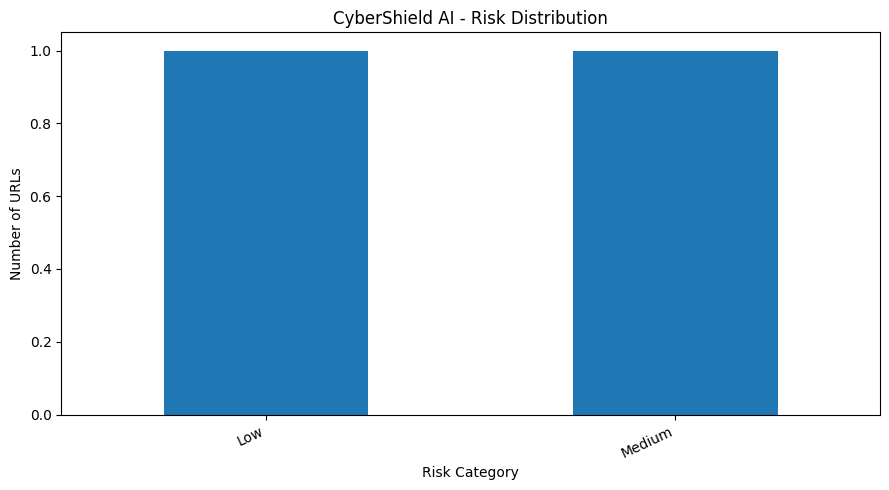

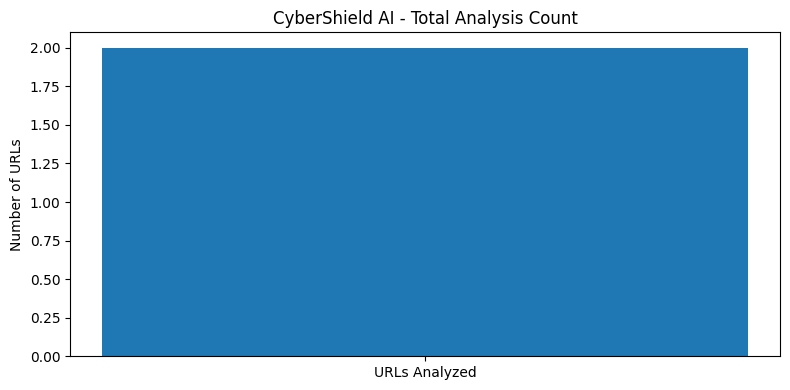

Dashboard charts generated successfully!


In [2]:

import pandas as pd
import matplotlib.pyplot as plt

# Check whether analysis history exists
if not analysis_history:
    print("First, analyze at least one URL!")
else:
    df = pd.DataFrame(analysis_history)

    # Chart 1: Risk distribution
    risk_counts = df["Risk"].value_counts()

    plt.figure(figsize=(9, 5))
    risk_counts.plot(kind="bar")
    plt.title("CyberShield AI - Risk Distribution")
    plt.xlabel("Risk Category")
    plt.ylabel("Number of URLs")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    # Chart 2: URLs analyzed
    plt.figure(figsize=(8, 4))
    plt.bar(["URLs Analyzed"], [len(df)])
    plt.title("CyberShield AI - Total Analysis Count")
    plt.ylabel("Number of URLs")
    plt.tight_layout()
    plt.show()

    print("Dashboard charts generated successfully!")


In [1]:

import re
import pandas as pd
from urllib.parse import urlparse
from IPython.display import display

# Store URL analysis results for the dashboard
if "analysis_history" not in globals():
    analysis_history = []

def analyze_url(url):
    url = url.strip()

    if not url:
        print("Please enter a URL.")
        return None

    # Add a scheme if the user did not provide one
    candidate = url if "://" in url else "https://" + url
    parsed = urlparse(candidate)
    hostname = parsed.hostname

    if not hostname:
        print("Invalid URL. Please enter a valid domain or URL.")
        return None

    reasons = []
    score = 0

    # Check for an IP address used as the hostname
    if re.fullmatch(r"(?:\d{1,3}\.){3}\d{1,3}", hostname):
        score += 2
        reasons.append("Uses an IP address instead of a domain name")

    # Check for unusually long URLs
    if len(candidate) > 75:
        score += 1
        reasons.append("Unusually long URL")

    # Check for suspicious URL patterns
    suspicious_words = [
        "login", "verify", "account", "password",
        "secure", "update", "banking", "confirm"
    ]
    found_words = [word for word in suspicious_words
                   if word in candidate.lower()]

    if len(found_words) >= 2:
        score += 2
        reasons.append("Multiple account or verification-related keywords")
    elif found_words:
        score += 1
        reasons.append("Account or verification-related keyword present")

    # Check for URL shorteners
    shorteners = [
        "bit.ly", "tinyurl.com", "t.co",
        "is.gd", "cutt.ly", "shorturl.at"
    ]
    if hostname.lower() in shorteners:
        score += 2
        reasons.append("Uses a URL-shortening service")

    # HTTPS is useful but does not guarantee a website is safe
    if parsed.scheme.lower() != "https":
        score += 1
        reasons.append("Does not use HTTPS")

    if score >= 4:
        risk = "High"
    elif score >= 2:
        risk = "Medium"
    else:
        risk = "Low"

    result = {
        "URL": url,
        "Domain": hostname,
        "Risk": risk,
        "Risk Score": score,
        "Reasons": "; ".join(reasons) if reasons else
                   "No suspicious patterns found by these basic rules"
    }

    analysis_history.append(result)
    display(pd.DataFrame([result]))
    return result


# Test using example URLs; these are illustrative, not verified malicious
test_urls = [
    "https://www.wikipedia.org",
    "http://example.com/login/verify-account"
]

for test_url in test_urls:
    analyze_url(test_url)


,URL,Domain,Risk,Risk Score,Reasons
0,https://www.wikipedia.org,www.wikipedia.org,Low,0,No suspicious patterns found by these basic rules


,URL,Domain,Risk,Risk Score,Reasons
0,http://example.com/login/verify-account,example.com,Medium,3,Multiple account or verification-related keywo...


In [3]:
requirements = """pandas
matplotlib
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [4]:

!pip -q install python-docx

from docx import Document
from docx.shared import Pt

doc = Document()

doc.add_heading("CyberShield AI", 0)
doc.add_heading(
    "Rule-Based URL Risk Analysis and Security Dashboard", level=1
)

doc.add_heading("1. Abstract", level=1)
doc.add_paragraph(
    "CyberShield AI is a beginner cybersecurity project that analyzes "
    "URLs using simple rule-based checks. It assigns a risk score based "
    "on URL characteristics and displays a risk category. A dashboard "
    "summarizes analyzed URLs."
)

doc.add_heading("2. Problem Statement", level=1)
doc.add_paragraph(
    "Suspicious URLs may contain misleading keywords, unusually long "
    "addresses, IP-based hosts, URL shorteners, or insecure HTTP links. "
    "This project demonstrates how these characteristics can be checked "
    "automatically."
)

doc.add_heading("3. Objectives", level=1)
for item in [
    "Analyze URL structure and hostname.",
    "Identify selected suspicious URL patterns.",
    "Calculate a simple rule-based risk score.",
    "Display URL analysis results.",
    "Visualize analysis history using charts."
]:
    doc.add_paragraph(item, style="List Bullet")

doc.add_heading("4. Technologies Used", level=1)
doc.add_paragraph(
    "Python, Pandas, Matplotlib, urllib.parse, Regular Expressions, "
    "Google Colab, and python-docx for report generation."
)

doc.add_heading("5. Methodology", level=1)
doc.add_paragraph(
    "The program parses a submitted URL and checks for selected signals, "
    "including IP-address hosts, URL length, account-related keywords, "
    "known URL-shortening domains, and absence of HTTPS. Points are "
    "combined into a simple score: 0–1 Low, 2–3 Medium, and 4 or more High."
)

doc.add_heading("6. Testing and Results", level=1)
doc.add_paragraph(
    "In an initial illustrative test, https://www.wikipedia.org received "
    "a Low risk score of 0. The example URL "
    "http://example.com/login/verify-account received a Medium score "
    "of 3. These results demonstrate the rules only; they do not prove "
    "that either website is safe or malicious."
)

doc.add_heading("7. Limitations", level=1)
doc.add_paragraph(
    "This is a rule-based prototype, not a trained machine-learning model. "
    "It does not verify website reputation, inspect page content, or "
    "measure detection accuracy against a labeled dataset. Risk labels "
    "are indicative and may produce false positives or false negatives."
)

doc.add_heading("8. Future Enhancements", level=1)
doc.add_paragraph(
    "Future work may include testing with a labeled dataset, evaluating "
    "precision and recall, adding reputable threat-intelligence sources, "
    "and building a user-friendly interface."
)

doc.add_heading("9. Conclusion", level=1)
doc.add_paragraph(
    "CyberShield AI demonstrates basic URL feature checks, rule-based "
    "risk scoring, and visualization of analysis history. Further "
    "validation is required before it can be used as a security tool."
)

doc.save("DudeBhuvanaSai_ProjectReport.docx")
print("Project report created successfully!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.0/253.0 kB 4.2 MB/s eta 0:00:00
Project report created successfully!


In [6]:
from google.colab import files
files.download("DudeBhuvanaSai_ProjectReport.docx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

readme = """# CyberShield AI

## Project Overview
CyberShield AI is a beginner cybersecurity project that analyzes URLs
using simple rule-based checks and displays risk summaries in charts.

## Objectives
- Inspect URL structure and hostname.
- Check selected suspicious URL patterns.
- Assign an indicative risk score.
- Visualize analysis history.

## Technologies
- Python
- Pandas
- Matplotlib
- Google Colab

## How It Works
The program checks selected URL features, such as IP-address hosts,
URL length, account-related keywords, URL shorteners, and HTTPS usage.
It combines these signals into a Low, Medium, or High risk category.

## Run Instructions
1. Open the project notebook in Google Colab.
2. Run the code cells from top to bottom.
3. Analyze URLs using the provided function.
4. Run the dashboard cell to generate charts.

## Dataset
The current prototype uses illustrative test URLs and rule-based checks.
It does not yet use a validated labeled dataset or a trained ML model.
Add a real dataset link here if one is incorporated in a future version.

## Limitations
Risk labels are heuristic estimates, not proof that a website is safe
or malicious. The prototype has not been validated using a labeled
dataset.

## Author
Dude Bhuvana Sai
"""

with open("README.md", "w", encoding="utf-8") as f:
    f.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [10]:
import os

for f in os.listdir("/content"):
    if f.endswith(".ipynb"):
        print(f)